
<p align="center"> In the Name of God </p>

<table style="width: 100%; text-align: center;">
  <tr>
    <td style="width: 20%;"><img src="https://i.ibb.co/yXKQmtZ/logo1.png" alt="Left Logo" width="100"></td>
    <td style="width: 60%;">
      <p>Faculty of Electrical and Computer Engineering</p>
      <p>Interactive learning - Fall 2023-2024</p>
      <p>Assignment Series 3</p>
      <p>Markov Decision Processes and Dynamic programming</p>
    </td>
    <td style="width: 20%;"><img src="https://i.ibb.co/wLjqFkw/logo2.png" alt="Right Logo" width="100"></td>
  </tr>
  
</table>
<p align="center">Fatemeh Mohammadi - 810199489</p>
<hr>



Please review the report as well,
     focusing on responses to questions and the **analysis of results in the implementation**.

# <font color = lightGreen> Problem 4: 
 </font>

# Import Libraries 

In [64]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import random
from tqdm.notebook import tqdm, trange
from typing import Optional
import numpy as np
from tqdm import trange
from typing import Optional
from itertools import product
from sklearn.model_selection import ParameterGrid


import warnings
warnings.filterwarnings("ignore")

# Environment and Parameter Setup

In [65]:
env = gym.make('CliffWalking-v0')

In [87]:
discount = 0.9

learning_rate = 0.1
reduced_learning_rate = 0.01
min_lr = 0.001

epsilon = 1.0
epsilon_decay = 0.99
min_epsilon = 0.01
#-----
param_grid = {
    'discount': [0.9, 0.95],
    'learning_rate': [0.1, 0.05, 0.01],
    'learning_rate_decay': [None, 0.01],
    'epsilon': [1.0, 0.5],
    'epsilon_decay': [None, 0.995, 0.99]
}
#-----
num_runs = 10
num_episodes = 200


# plot result Functions

In [88]:
def plot_result(total_reward_per_run, regret_per_run, num_episodes , num_runs,
              figsize = (15,4), title = ''):

  fig, ax = plt.subplots(figsize = figsize)

  # Total_reward
  mean_total_reward_per_run = np.mean(np.array(total_reward_per_run), axis = 0)
  std_total_reward_per_run = np.std(np.array(total_reward_per_run), axis = 0)
  up_bound_total_reward = mean_total_reward_per_run + 1.96 * std_total_reward_per_run/np.sqrt(num_runs)
  low_bound_total_reward = mean_total_reward_per_run - 1.96 * std_total_reward_per_run/np.sqrt(num_runs)
  ax.plot(range(num_episodes), mean_total_reward_per_run, label = 'Total_Reward')
  ax.fill_between(range(num_episodes), low_bound_total_reward, up_bound_total_reward, alpha = 0.5)


  # # Regret
  if regret_per_run != []:
    mean_regret_per_run = np.mean(np.array(regret_per_run), axis = 0)
    std_regret_per_run = np.std(np.array(regret_per_run), axis = 0)
    up_bound_regret = mean_regret_per_run + 1.96 * std_regret_per_run/np.sqrt(num_runs)
    low_bound_regret = mean_regret_per_run - 1.96 * std_regret_per_run/np.sqrt(num_runs)
    ax.plot(range(num_episodes), mean_regret_per_run, label = 'Regret')
    ax.fill_between(range(num_episodes),low_bound_regret, up_bound_regret, alpha = 0.5)


  plt.title(title)
  plt.ylabel('Reward')
  plt.xlabel('episode')
  plt.legend()
  plt.show()

# A.

In [89]:
#from Hands_on3:

class QLearning:

  def __init__(self, env, learning_rate, discount, epsilon,
               epsilon_decay:Optional[float]= None, min_epsilon:Optional[float] = None ,
               learning_rate_decay: Optional[float] = None, min_lr:Optional[float] = None):

    self.env = env
    self.state_size = env.observation_space.n
    self.action_space = env.action_space
    self.action_size = env.action_space.n
    self.q_table = np.zeros((self.state_size, self.action_size))

    self.learning_rate = learning_rate
    self.discount = discount
    self.epsilon = epsilon
    self.epsilon_decay = epsilon_decay

    self.learning_rate_decay = learning_rate_decay #for Decreasing Learning Rate
    self.initial_lr = learning_rate
    self.min_lr = min_lr

    self.min_epsilon = min_epsilon

    self.optimal_reward = -13  #the optimal reward is -13 for CliffWalking-v0 (13 steps to the goal)


  def get_action(self, state):
    if np.random.rand() < self.epsilon:
      return self.env.action_space.sample()
    else:
      return np.argmax(self.q_table[state])

  def train(self, episodes):

    regrets = []
    total_rewards = []
    frames = []

    for episode in trange(episodes):

      state, _ = self.env.reset()
      total_reward = 0

      while True:

        action = self.get_action(state)
        next_state, reward, terminated, truncated, _ = self.env.step(action)

        current_q = self.q_table[state, action]
        next_max_q = np.max(self.q_table[next_state])

        # Write Q-Learning updating rule
        new_q = current_q + self.learning_rate*(reward + self.discount*next_max_q - current_q)
        self.q_table[state , action] = new_q

        total_reward += reward
        state = next_state

        if episode == episodes-1:
          frames.append(self.env.render())

        if terminated or truncated:
          # Calculate regret
          regret = self.optimal_reward -  total_reward
          regrets.append(regret)
          total_rewards.append(total_reward)
          break

      if (self.epsilon_decay):
        self.epsilon = max(self.min_epsilon, self.epsilon_decay * self.epsilon )

      if (self.learning_rate_decay):
        self.learning_rate = max(self.min_lr ,self.initial_lr / (1 + self.learning_rate_decay * episode))

    return regrets, total_rewards, frames

In [90]:
def run_qlearning_experiment(env, num_runs, num_episodes, learning_rate, discount, epsilon,
                            epsilon_decay=None, min_epsilon=None,
                            learning_rate_decay=None, min_lr=None):
    total_rewards_per_run = []
    regrets_per_run = []

    for run in range(num_runs):
        print(f"Running experiment {run+1}/{num_runs}...")

        ql_agent = QLearning(
            env,
            learning_rate=learning_rate, discount=discount, epsilon=epsilon,
            epsilon_decay=epsilon_decay, min_epsilon=min_epsilon,
            learning_rate_decay=learning_rate_decay, min_lr=min_lr )

        regrets, total_rewards, _ = ql_agent.train(num_episodes)

        total_rewards_per_run.append(total_rewards)
        regrets_per_run.append(regrets)

    return total_rewards_per_run, regrets_per_run


In [91]:
def grid_search(env, param_grid, num_episodes, num_runs):
    best_reward = -float('inf')
    best_params = None
    results = []

    grid = ParameterGrid(param_grid)

    for params in grid:
        print(f"Evaluating combination: {params}")

        lr = params['learning_rate']
        discount = params['discount']
        epsilon = params['epsilon']
        epsilon_decay = params['epsilon_decay']
        lr_decay = params['learning_rate_decay']

        total_rewards_per_run, regrets_per_run = run_qlearning_experiment(
            env, num_runs, num_episodes, lr, discount, epsilon,
            epsilon_decay=epsilon_decay, min_epsilon=0.01,
            learning_rate_decay=lr_decay, min_lr=0.001)

        mean_total_reward = np.mean([np.sum(reward) for reward in total_rewards_per_run])

        if mean_total_reward > best_reward:
            best_reward = mean_total_reward
            best_params = params

        results.append((params, mean_total_reward))

    return best_params, best_reward, results

## Q-learning with Learning Rate 0.1

Running with constant learning rate...
Running experiment 1/10...


100%|██████████| 200/200 [00:00<00:00, 333.93it/s]


Running experiment 2/10...


100%|██████████| 200/200 [00:00<00:00, 314.85it/s]


Running experiment 3/10...


...

100%|██████████| 200/200 [00:00<00:00, 414.39it/s]


Running experiment 9/10...


100%|██████████| 200/200 [00:00<00:00, 342.85it/s]


Running experiment 10/10...


100%|██████████| 200/200 [00:00<00:00, 517.93it/s]


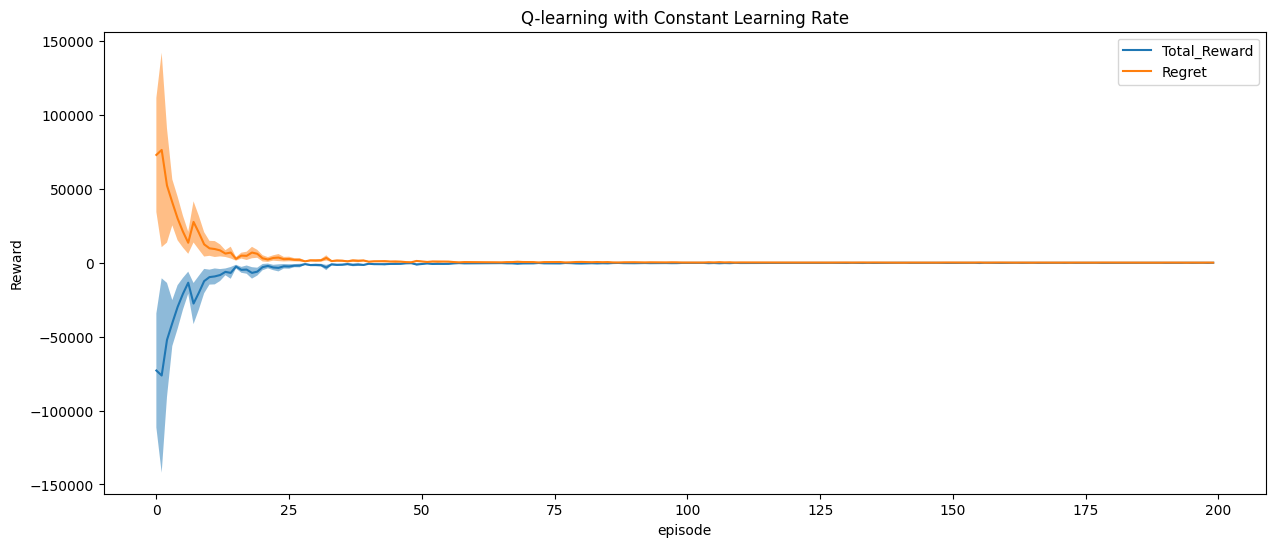

In [92]:
print("Running with constant learning rate...")
total_rewards_const_lr, regrets_const_lr = run_qlearning_experiment(
    env, num_runs, num_episodes, learning_rate, discount, epsilon,
    epsilon_decay=epsilon_decay, min_epsilon=min_epsilon)

plot_result(total_rewards_const_lr, regrets_const_lr, num_episodes, num_runs,
                figsize=(15, 6), title="Q-learning with Constant Learning Rate")

In [93]:
max(max(total_rewards_const_lr))

-13

## Q-learning with decreasing Learning Rate 


Running with decreasing learning rate...
Running experiment 1/10...


100%|██████████| 200/200 [00:00<00:00, 296.48it/s]


Running experiment 2/10...


100%|██████████| 200/200 [00:00<00:00, 394.63it/s]


Running experiment 3/10...


...

100%|██████████| 200/200 [00:00<00:00, 415.99it/s]


Running experiment 9/10...


100%|██████████| 200/200 [00:00<00:00, 467.32it/s]


Running experiment 10/10...


100%|██████████| 200/200 [00:00<00:00, 441.46it/s]


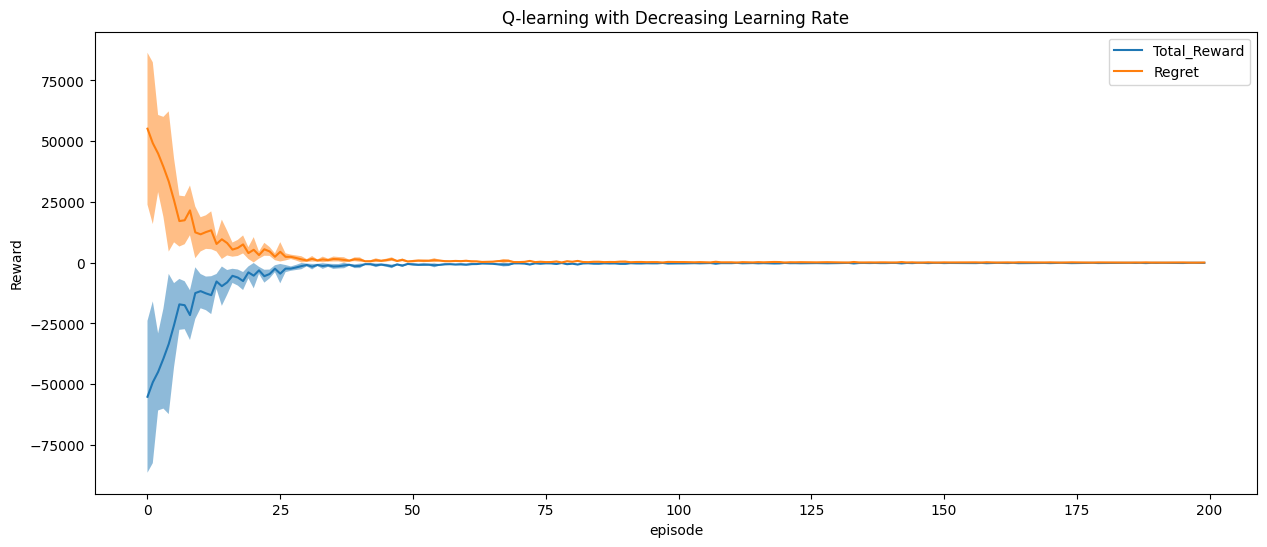

In [94]:
print("Running with decreasing learning rate...")
total_rewards_dec_lr, regrets_dec_lr = run_qlearning_experiment(
    env, num_runs, num_episodes, learning_rate, discount,  epsilon,
    epsilon_decay=epsilon_decay, min_epsilon=min_epsilon,
    learning_rate_decay=learning_rate, min_lr=min_lr)

plot_result(total_rewards_dec_lr, regrets_dec_lr, num_episodes, num_runs,
                figsize=(15, 6), title="Q-learning with Decreasing Learning Rate")


In [95]:
max(max(total_rewards_dec_lr))

-13

# B.

In [ ]:
#from Hands_on3:

class SARSA:

  def __init__(self, env, learning_rate = 0.1, discount = 0.99, epsilon = 1,
               epsilon_decay:Optional[float]= None, min_epsilon:Optional[float] = None):

    self.env = env
    self.state_size = env.observation_space.n
    self.action_space = env.action_space
    self.action_size = env.action_space.n
    self.q_table = np.zeros((self.state_size, self.action_size))

    self.learning_rate = learning_rate
    self.discount = discount
    self.epsilon = epsilon
    self.epsilon_decay = epsilon_decay
    self.epsilon_min = min_epsilon

    self.optimal_reward = -13  #the optimal reward is -13 for CliffWalking-v0 (13 steps to the goal)


  def get_action(self, state):
    if np.random.rand() < self.epsilon:
      return self.env.action_space.sample()
    else:
      return np.argmax(self.q_table[state])

  def train(self, episodes):

    regrets = []
    total_rewards = []
    frames = []

    for episode in trange(episodes):

      state, _ = self.env.reset()
      action = self.get_action(state)
      total_reward = 0
      frames_per_episode = []

      while True:

        next_state, reward, terminated, truncated, _  = self.env.step(action)
        next_action = self.get_action(next_state)

        current_q = self.q_table[state, action]
        next_q = self.q_table[next_state, next_action]

        # Write SARSA updating rule
        new_q = current_q + self.learning_rate*(reward + self.discount*next_q - current_q)
        self.q_table[state , action] = new_q


        total_reward += reward
        state = next_state
        action = next_action

        if terminated or truncated:
          # Calcualte regret
          regret = self.optimal_reward - total_reward
          regrets.append(regret)
          total_rewards.append(total_reward)
          break

        if episode % 20 == 0:
          frames_per_episode.append(self.env.render())

      if frames_per_episode:
        frames.append(frames_per_episode)

      if (self.epsilon_decay) and (self.epsilon > self.epsilon_min):
        self.epsilon = self.epsilon * self.epsilon_decay

    return regrets, total_rewards, frames

In [ ]:
#using the SARSA class and modifying it

class TreeBackupNStep:

  def __init__(self, env, learning_rate, discount, epsilon, n,
               epsilon_decay:Optional[float]= None, min_epsilon:Optional[float] = None):

    self.env = env
    self.state_size = env.observation_space.n
    self.action_space = env.action_space
    self.action_size = env.action_space.n
    self.q_table = np.zeros((self.state_size, self.action_size))

    self.learning_rate = learning_rate
    self.discount = discount
    self.epsilon = epsilon
    self.epsilon_decay = epsilon_decay
    self.epsilon_min = min_epsilon

    self.optimal_reward = -13  #the optimal reward is -13 for CliffWalking-v0 (13 steps to the goal)

    self.n = n

  def get_action(self, state):
    if np.random.rand() < self.epsilon:
      return self.env.action_space.sample()
    else:
      return np.argmax(self.q_table[state])

  def train(self, episodes):

    regrets = []
    total_rewards = []
    frames = []

    for episode in trange(episodes):

      state, _ = self.env.reset()
      action = self.get_action(state)
      total_reward = 0
      frames_per_episode = []

      buffer_SAR = [] #initialize an empty list for storing the state-action-reward for steps
      time_step = 0


      while True:

        next_state, reward, terminated, truncated, _  = self.env.step(action)
        buffer_SAR.append((state, action, reward))

        if len(buffer_SAR) > self.n:
                    buffer_SAR.pop(0)

        if len(buffer_SAR) == self.n:
                    G = sum([self.discount**i * r for i, (s, a, r) in enumerate(buffer_SAR)]) #calculate the n-step return (tree backup)
                    state_t, action_t, reward_t = buffer_SAR[0]

                    #estimate the value of the next state
                    if not terminated:
                        next_value = np.max(self.q_table[next_state])
                    else:
                        next_value = 0  #if terminated, value = 0


                    self.q_table[state_t, action_t] += self.learning_rate * (G + self.discount**self.n * next_value - self.q_table[state_t, action_t]) #update the Q-value

        time_step += 1

        total_reward += reward
        state = next_state
        action = self.get_action(state)

        if terminated or truncated:
          # Calcualte regret
          regret = self.optimal_reward - total_reward
          regrets.append(regret)
          total_rewards.append(total_reward)
          break

        if episode % 20 == 0:
          frames_per_episode.append(self.env.render())

      if frames_per_episode:
        frames.append(frames_per_episode)

      if (self.epsilon_decay) and (self.epsilon > self.epsilon_min):
        self.epsilon = self.epsilon * self.epsilon_decay

    return regrets, total_rewards, frames

## Simulation:

In [ ]:
def run_sarsa_experiment(env, num_runs, num_episodes, learning_rate, discount, epsilon,
                         epsilon_decay=None, min_epsilon=None):
    total_rewards_per_run = []
    regrets_per_run = []

    for run in range(num_runs):
        print(f"Running SARSA experiment {run+1}/{num_runs}...")

        sarsa_agent = SARSA(
            env,
            learning_rate=learning_rate,
            discount=discount,
            epsilon=epsilon,
            epsilon_decay=epsilon_decay,
            min_epsilon=min_epsilon
        )

        regrets, total_rewards, _ = sarsa_agent.train(num_episodes)

        total_rewards_per_run.append(total_rewards)
        regrets_per_run.append(regrets)

    return total_rewards_per_run, regrets_per_run


In [ ]:
total_rewards_sarsa, regrets_sarsa = run_sarsa_experiment(
    env, num_runs, num_episodes, learning_rate, discount, epsilon,
    epsilon_decay=epsilon_decay, min_epsilon=min_epsilon
)

plot_result(total_rewards_sarsa, regrets_sarsa, num_episodes=num_episodes, num_runs=num_runs,
            figsize=(15, 6), title="SARSA Algorithm")

In [ ]:
def run_tree_backup_experiment(env, num_runs, num_episodes, learning_rate, discount, epsilon, n_values,
                                epsilon_decay=None, min_epsilon=None):
    total_rewards_per_n = {n: [] for n in n_values}
    regrets_per_n = {n: [] for n in n_values}

    for n in n_values:
        print(f"Running Tree Backup n-step with n={n}...")

        tree_backup_agent = TreeBackupNStep(
            env,
            learning_rate=learning_rate,
            discount=discount,
            epsilon=epsilon,
            n=n,
            epsilon_decay=epsilon_decay,
            min_epsilon=min_epsilon
        )

        regrets_n, total_rewards_n, _ = tree_backup_agent.train(num_episodes)

        total_rewards_per_n[n].append(total_rewards_n)
        regrets_per_n[n].append(regrets_n)

    return total_rewards_per_n, regrets_per_n


In [ ]:
n_values = [1, 3, 5]
total_rewards_tree_backup, regrets_tree_backup = run_tree_backup_experiment(
    env, num_runs, num_episodes, learning_rate, discount, epsilon, n_values,
    epsilon_decay=epsilon_decay, min_epsilon=min_epsilon
)

total_rewards_tree_backup, regrets_tree_backup = run_tree_backup_experiment(
    env, num_runs, num_episodes, learning_rate, discount, epsilon, n_values,
    epsilon_decay=epsilon_decay, min_epsilon=min_epsilon
)

for n in n_values:
    plot_result(total_rewards_tree_backup[n], regrets_tree_backup[n], num_episodes, num_runs,
                figsize=(15, 6), title=f"Tree Backup n-step (n={n})")

# C.

In [ ]:
#from Hands_on3:

class OffPolicyMonteCarlo:

    def __init__(self, env, discount, epsilon,
                 epsilon_decay:Optional[float]= None, min_epsilon:Optional[float] = None):
        self.env = env
        self.state_size = env.observation_space.n
        self.action_size = env.action_space.n
        self.q_table = np.zeros((self.state_size, self.action_size))

        self.returns_sum = np.zeros((self.state_size, self.action_size))
        self.returns_count = np.zeros((self.state_size, self.action_size))

        self.discount = discount
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = min_epsilon

    def get_action_behavior_policy(self, state): #e-greedy
        if np.random.rand() < self.epsilon:
            return self.env.action_space.sample()
        else:
            return np.argmax(self.q_table[state])

    def get_action_target_policy(self, state):
        #target policy: greedy (exploitation)
        return np.argmax(self.q_table[state])

    def train(self, episodes):
        total_rewards = []


        for i in trange(episodes):
            state, _ = self.env.reset()
            episode = []

            while True:
                action = self.get_action_behavior_policy(state)
                next_state, reward, terminated, truncated, _ = self.env.step(action)
                episode.append((state, action, reward))
                state = next_state
                if terminated or truncated:
                    break

            G = 0
            visited_state_action_pairs = set()
            for state, action, reward in reversed(episode):
                G = self.discount * G + reward

                #Importance Sampling (off-policy correction)
                behavior_policy_prob = 1.0 if np.argmax(self.q_table[state]) == action else self.epsilon / (self.action_size - 1)
                target_policy_prob = 1.0 if np.argmax(self.q_table[state]) == action else 0.0
                rho = target_policy_prob / behavior_policy_prob

                if (state, action) not in visited_state_action_pairs:
                    self.returns_sum[state, action] += rho * G
                    self.returns_count[state, action] += rho
                    self.q_table[state, action] = self.returns_sum[state, action] / self.returns_count[state, action]
                    visited_state_action_pairs.add((state, action))

            total_reward = sum(x[2] for x in episode)
            total_rewards.append(total_reward)


            if (self.epsilon_decay) and (self.epsilon > self.epsilon_min):
                self.epsilon *= self.epsilon_decay

        return total_rewards


In [ ]:
def run_off_policy_monte_carlo_experiment(env, num_runs, num_episodes, learning_rate, discount, epsilon,
                                           epsilon_decay=None, min_epsilon=None):
    total_rewards_per_run = []

    for run in range(num_runs):
        print(f"Running Off-Policy Monte Carlo experiment {run+1}/{num_runs}...")

        off_policy_mc_agent = OffPolicyMonteCarlo(
            env, discount=discount, epsilon=epsilon,
            epsilon_decay=epsilon_decay, min_epsilon=min_epsilon
        )

        total_rewards = off_policy_mc_agent.train(num_episodes)
        total_rewards_per_run.append(total_rewards)

    return total_rewards_per_run


In [ ]:

total_rewards_off_policy_mc = run_off_policy_monte_carlo_experiment(
    env, num_runs, num_episodes, learning_rate, discount, epsilon = 0.1)

plot_result(   , [], num_episodes, num_runs, figsize=(15, 6),
            title="Off-Policy Monte Carlo")

In [ ]:
class OffPolicyMonteCarlo2:

    def __init__(self, env, discount, epsilon,
                 epsilon_decay:Optional[float]= None, min_epsilon:Optional[float] = None):
        self.env = env
        self.state_size = env.observation_space.n
        self.action_size = env.action_space.n
        self.q_table = np.zeros((self.state_size, self.action_size))

        self.returns_sum = np.zeros((self.state_size, self.action_size))
        self.returns_count = np.zeros((self.state_size, self.action_size))

        self.discount = discount
        self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = min_epsilon

    def get_action_behavior_policy(self, state): #e-greedy
        if np.random.rand() < self.epsilon:
            return self.env.action_space.sample()
        else:
            return np.argmax(self.q_table[state])

    def get_action_target_policy(self, state):
        #target policy: greedy (exploitation)
        return np.argmax(self.q_table[state])

    def train(self, episodes):
        total_rewards = []

        max_steps_per_episode = 1000 #horizon

        for i in trange(episodes):
            state, _ = self.env.reset()
            episode = []

            i == 0
            while i < max_steps_per_episode:
                i += 1
                action = self.get_action_behavior_policy(state)
                next_state, reward, terminated, truncated, _ = self.env.step(action)

                if terminated or truncated:
                    episode.append((state, action, reward))
                    state = next_state
                    break

                if i == max_steps_per_episode:
                    reward = -10000
                episode.append((state, action, reward))
                state = next_state


            G = 0
            visited_state_action_pairs = set()
            for state, action, reward in reversed(episode):
                G = self.discount * G + reward

                #Importance Sampling (off-policy correction)
                behavior_policy_prob = 1.0 if np.argmax(self.q_table[state]) == action else self.epsilon / (self.action_size - 1)
                target_policy_prob = 1.0 if np.argmax(self.q_table[state]) == action else 0.0
                rho = target_policy_prob / behavior_policy_prob

                if (state, action) not in visited_state_action_pairs:
                    self.returns_sum[state, action] += rho * G
                    self.returns_count[state, action] += rho
                    self.q_table[state, action] = self.returns_sum[state, action] / self.returns_count[state, action]
                    visited_state_action_pairs.add((state, action))

            total_reward = sum(x[2] for x in episode)
            total_rewards.append(total_reward)


            if (self.epsilon_decay) and (self.epsilon > self.epsilon_min):
                self.epsilon *= self.epsilon_decay

        return total_rewards

In [ ]:
def run_off_policy_monte_carlo_2_experiment(env, num_runs, num_episodes, learning_rate, discount, epsilon,
                                           epsilon_decay=None, min_epsilon=None):
    total_rewards_per_run = []

    for run in range(num_runs):
        print(f"Running Off-Policy Monte Carlo experiment {run+1}/{num_runs}...")

        off_policy_mc_agent = OffPolicyMonteCarlo2(
            env, discount=discount, epsilon=epsilon,
            epsilon_decay=epsilon_decay, min_epsilon=min_epsilon
        )

        total_rewards = off_policy_mc_agent.train(num_episodes)
        total_rewards_per_run.append(total_rewards)

    return total_rewards_per_run

In [ ]:

total_rewards_off_policy_mc = run_off_policy_monte_carlo_2_experiment(
    env, num_runs, num_episodes, learning_rate, discount, epsilon = 0.1)

plot_result(total_rewards_off_policy_mc, [], num_episodes, num_runs, figsize=(15, 6),
            title="Off-Policy Monte Carlo")

In [ ]:
total_rewards_off_policy_mc = run_off_policy_monte_carlo_experiment(
    env, num_runs, num_episodes, learning_rate, discount, epsilon, epsilon_decay, min_epsilon)

plot_result(total_rewards_off_policy_mc, [], num_episodes, num_runs, figsize=(15, 6),
            title="Off-Policy Monte Carlo")